# Programming Assignment 3 — Poucos Rótulos: Fauna em Câmeras Trap com Dados Não Rotulados

**Disciplina:** Aprendizado Profundo  
**Professor:** Dario Oliveira | **Monitor:** Erick Brito  
**Alunos:** Henrique Gabriel Gasparelo & José Thevez Gomes Guedes  

---

### Objetivo do Projeto
Construir um classificador de espécies em imagens de câmeras trap (*ENA24-detection*, 21 classes) em um regime severo de escassez de dados anotados (**5 rótulos por classe**, totalizando 105 imagens rotuladas) e milhares de imagens não rotuladas (**6.505 imagens**), explorando a **Trilha C (Professor e Aluno)** na Parte 1.

### Restrições de Engenharia
1. **Teto de Parâmetros:** Máximo de **12 milhões de parâmetros** (`sum(p.numel() for p in model.parameters()) <= 12_000_000`).
2. **Ambiente:** Modelo leve executável em **CPU**, sem internet, classificando o conjunto de teste em menos de 10 minutos.
3. **Métrica Principal:** **F1 Macro** no conjunto de teste, equilibrando o peso entre classes abundantes (ex: urso) e raras (ex: cavalo).

## 1. Setup, Imports e Fixação de Seeds

In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
os.environ['NO_ALBUMENTATIONS_UPDATE'] = '1'

import pandas as pd
from IPython.display import display

import torch
import torch.nn as nn

from src.utils import seed_everything, get_device
from src.data import load_class_mapping, get_supervised_dataloaders
from src.models import build_model
from src.training import train_supervised
from src.metrics import (
    evaluate_model,
    plot_training_curves,
    plot_comparison_curves,
    plot_confusion_matrix,
    detect_overfitting_epoch,
    build_part0_summary_table,
    build_per_class_f1_table,
)

SEED = 42
seed_everything(SEED)
device = get_device(prefer_gpu=True)
print(f"Dispositivo de treinamento ativo: {device}")

Dispositivo de treinamento ativo: mps


## 2. Verificação de Regras de Engenharia (Teto de 12M Parâmetros)

In [2]:
print("--- Verificando Parte 0 (a): SmallCNN ---")
_ = build_model(arch="small_cnn", num_classes=21, pretrained=False, verbose=True)

print("\n--- Verificando Parte 0 (b) & Backbone Principal: ResNet-18 ---")
_ = build_model(arch="resnet18", num_classes=21, pretrained=False, verbose=True)

--- Verificando Parte 0 (a): SmallCNN ---
Total de parâmetros: 424,501 (Treináveis: 424,501)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.

--- Verificando Parte 0 (b) & Backbone Principal: ResNet-18 ---
Total de parâmetros: 11,187,285 (Treináveis: 11,187,285)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.


## 3. Exploração dos Dados (ENA24) e Construção dos DataLoaders

In [3]:
DATA_DIR = "data"
LABELS_DIR = os.path.join(DATA_DIR, "labels")
IMAGES_DIR = os.path.join(DATA_DIR, "images")

class_to_idx, idx_to_class, class_names = load_class_mapping(os.path.join(DATA_DIR, "classes.csv"))
print(f"✓ Total de classes carregadas: {len(class_names)}")

df_r1 = pd.read_csv(os.path.join(LABELS_DIR, "rotulos_1.csv"))
df_r5 = pd.read_csv(os.path.join(LABELS_DIR, "rotulos_5.csv"))
df_r20 = pd.read_csv(os.path.join(LABELS_DIR, "rotulos_20.csv"))
df_val = pd.read_csv(os.path.join(LABELS_DIR, "val.csv"))
df_test = pd.read_csv(os.path.join(LABELS_DIR, "test_public.csv"))

n_train_imgs = len([f for f in os.listdir(os.path.join(IMAGES_DIR, "train")) if f.endswith('.jpg')])
n_val_imgs = len([f for f in os.listdir(os.path.join(IMAGES_DIR, "val")) if f.endswith('.jpg')])
n_test_imgs = len([f for f in os.listdir(os.path.join(IMAGES_DIR, "test_public")) if f.endswith('.jpg')])

print(f"✓ rotulos_1: {len(df_r1)} anotações (1 por classe)")
print(f"✓ rotulos_5: {len(df_r5)} anotações (5 por classe - Orçamento Padrão)")
print(f"✓ rotulos_20: {len(df_r20)} anotações (20 por classe)")
print(f"✓ Validação (val.csv): {len(df_val)} amostras | Imagens em disco: {n_val_imgs}")
print(f"✓ Teste Público (test_public.csv): {len(df_test)} amostras | Imagens em disco: {n_test_imgs}")
print(f"✓ Pool não rotulado (images/train): {n_train_imgs} imagens")

✓ Total de classes carregadas: 21
✓ rotulos_1: 21 anotações (1 por classe)
✓ rotulos_5: 105 anotações (5 por classe - Orçamento Padrão)
✓ rotulos_20: 420 anotações (20 por classe)
✓ Validação (val.csv): 202 amostras | Imagens em disco: 202
✓ Teste Público (test_public.csv): 811 amostras | Imagens em disco: 811
✓ Pool não rotulado (images/train): 6505 imagens


## 4. Parte 0 — O Piso (Baseline Supervisionado com 105 Imagens)

Treinamos dois classificadores supervisionados usando exclusivamente os **105 exemplos** de `rotulos_5.csv` (5 imagens por classe), selecionando a melhor época pelo **F1 Macro no `val` (202 imagens)**:
- **Versão (a) — `SmallCNN` (424.501 parâmetros):** CNN de 4 blocos convolucionais treinada do zero.
- **Versão (b) — `ResNet-18` (11.187.285 parâmetros):** Backbone principal do trabalho partindo de pesos pré-treinados na ImageNet com *fine-tuning* (`lr=5e-4` na cabeça linear e `lr=1e-4` no backbone).

### 4.1 Treinamento e Avaliação da Versão (a) — `SmallCNN` do Zero

In [4]:
seed_everything(SEED)
train_loader_a, val_loader, test_loader, class_to_idx, idx_to_class, class_names = get_supervised_dataloaders(
    data_dir=DATA_DIR, budget=5, batch_size=16, img_size=224
)

model_a = build_model(arch="small_cnn", num_classes=len(class_names), pretrained=False, dropout=0.3, verbose=True)
ckpt_a = f"checkpoints/part0a_small_cnn_b5_s{SEED}.pt"

model_a, history_a, best_ep_a, best_val_f1_a = train_supervised(
    model=model_a,
    train_loader=train_loader_a,
    val_loader=val_loader,
    device=device,
    epochs=45,
    lr=1e-3,
    backbone_lr_mult=1.0,
    weight_decay=1e-4,
    label_smoothing=0.05,
    num_classes=len(class_names),
    arch_name="small_cnn",
    checkpoint_path=ckpt_a,
    verbose=True,
)

eval_criterion = nn.CrossEntropyLoss()
test_metrics_a = evaluate_model(model_a, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))
diag_a = detect_overfitting_epoch(history_a)

print(
    f"\n-> [Resultado Parte 0 (a) - SmallCNN] "
    f"Val F1: {best_val_f1_a:.4f} (Época {best_ep_a}) | "
    f"Test Public F1 Macro: {test_metrics_a['f1_macro']:.4f} | "
    f"Test Public Acc: {test_metrics_a['accuracy']:.4f}"
)

Total de parâmetros: 424,501 (Treináveis: 424,501)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.
Época 01/45 | Train Loss: 3.0750 | Train F1: 0.0345 (Acc: 0.086) | Val Loss: 3.0577 | Val F1: 0.0059 (Acc: 0.035) ★ [Melhor Val F1]
Época 02/45 | Train Loss: 2.9385 | Train F1: 0.0986 (Acc: 0.133) | Val Loss: 3.0313 | Val F1: 0.0273 (Acc: 0.040) ★ [Melhor Val F1]
Época 03/45 | Train Loss: 2.8271 | Train F1: 0.1252 (Acc: 0.162) | Val Loss: 2.9777 | Val F1: 0.0532 (Acc: 0.089) ★ [Melhor Val F1]
Época 04/45 | Train Loss: 2.7854 | Train F1: 0.1363 (Acc: 0.200) | Val Loss: 2.8714 | Val F1: 0.0654 (Acc: 0.134) ★ [Melhor Val F1]
Época 05/45 | Train Loss: 2.6957 | Train F1: 0.1587 (Acc: 0.219) | Val Loss: 2.8084 | Val F1: 0.0881 (Acc: 0.163) ★ [Melhor Val F1]
Época 07/45 | Train Loss: 2.5725 | Train F1: 0.2380 (Acc: 0.276) | Val Loss: 2.8014 | Val F1: 0.1400 (Acc: 0.198) ★ [Melhor Val F1]
Época 10/45 | Train Loss: 2.5190 | Train F1: 0.2091 (Acc: 0.229) | Val Loss: 2.8294 | Va

### 4.2 Treinamento e Avaliação da Versão (b) — `ResNet-18` (ImageNet Fine-Tuning)

In [5]:
seed_everything(SEED)
train_loader_b, val_loader, test_loader, class_to_idx, idx_to_class, class_names = get_supervised_dataloaders(
    data_dir=DATA_DIR, budget=5, batch_size=16, img_size=224
)

model_b = build_model(arch="resnet18", num_classes=len(class_names), pretrained=True, dropout=0.2, verbose=True)
ckpt_b = f"checkpoints/part0b_resnet18_b5_s{SEED}.pt"

model_b, history_b, best_ep_b, best_val_f1_b = train_supervised(
    model=model_b,
    train_loader=train_loader_b,
    val_loader=val_loader,
    device=device,
    epochs=40,
    lr=5e-4,
    backbone_lr_mult=0.2,
    weight_decay=1e-4,
    label_smoothing=0.05,
    num_classes=len(class_names),
    arch_name="resnet18",
    checkpoint_path=ckpt_b,
    verbose=True,
)

test_metrics_b = evaluate_model(model_b, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))

print(
    f"\n-> [Resultado Parte 0 (b) - ResNet-18] "
    f"Val F1: {best_val_f1_b:.4f} (Época {best_ep_b}) | "
    f"Test Public F1 Macro: {test_metrics_b['f1_macro']:.4f} | "
    f"Test Public Acc: {test_metrics_b['accuracy']:.4f}"
)

Total de parâmetros: 11,187,285 (Treináveis: 11,187,285)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.
Época 01/40 | Train Loss: 3.2908 | Train F1: 0.0721 (Acc: 0.086) | Val Loss: 2.9223 | Val F1: 0.1161 (Acc: 0.163) ★ [Melhor Val F1]
Época 02/40 | Train Loss: 2.3458 | Train F1: 0.3540 (Acc: 0.390) | Val Loss: 2.6196 | Val F1: 0.1825 (Acc: 0.223) ★ [Melhor Val F1]
Época 03/40 | Train Loss: 1.8384 | Train F1: 0.6676 (Acc: 0.676) | Val Loss: 2.4368 | Val F1: 0.3278 (Acc: 0.351) ★ [Melhor Val F1]
Época 04/40 | Train Loss: 1.4088 | Train F1: 0.8336 (Acc: 0.838) | Val Loss: 2.3420 | Val F1: 0.3488 (Acc: 0.366) ★ [Melhor Val F1]
Época 05/40 | Train Loss: 1.0873 | Train F1: 0.9026 (Acc: 0.905) | Val Loss: 2.3187 | Val F1: 0.3549 (Acc: 0.366) ★ [Melhor Val F1]
Época 06/40 | Train Loss: 0.8856 | Train F1: 0.9227 (Acc: 0.924) | Val Loss: 2.2873 | Val F1: 0.3798 (Acc: 0.381) ★ [Melhor Val F1]
Época 07/40 | Train Loss: 0.7407 | Train F1: 0.9712 (Acc: 0.971) | Val Loss: 2.247

### 4.3 Comparativo Consolidado: Parte 0 (a) vs. Parte 0 (b) vs. Teto de Referência

In [6]:
p0_table = build_part0_summary_table(
    model_a=model_a,
    best_ep_a=best_ep_a,
    best_val_f1_a=best_val_f1_a,
    test_metrics_a=test_metrics_a,
    model_b=model_b,
    best_ep_b=best_ep_b,
    best_val_f1_b=best_val_f1_b,
    test_metrics_b=test_metrics_b,
    ceiling_f1=0.6860,
)
display(p0_table)

,Modelo / Versão,Parâmetros,Melhor Época (val),Val F1 Macro,Test Public F1 Macro,Test Public Acurácia
0,Parte 0 (a) — SmallCNN (Do Zero),"424,501",40,0.1929,0.1536,0.1665
1,Parte 0 (b) — ResNet-18 (ImageNet Fine-Tuning),"11,187,285",21,0.4246,0.4651,0.5068
2,Teto de Referência — ResNet-18 (6.505 rótulos),"11,187,285",-,-,0.6860,-


### 4.4 Curvas de Treino e Validação da Versão (b) — Em que época ela começa a decorar?

- **Início da memorização (*overfitting*):** Com apenas 105 imagens (5 por classe), a `ResNet-18` atinge **`> 90%` de F1 Macro e acurácia no treino já na Época 5** (`Train F1 = 0.9026`, `Train Acc = 0.905`), e chega a **`97%–99%` entre as Épocas 7 e 10**.
- **Divergência da Loss:** A *Cross-Entropy Loss* de validação atinge seu ponto mínimo na **Época 12** (`Val Loss = 2.2021`). A partir daí, a loss de validação volta a subir ligeiramente enquanto a loss de treino cai até o limite inferior do *label smoothing* (`~0.39`).
- **Seleção pelo `val`:** O melhor F1 Macro de validação (`0.4246`) ocorre na **Época 21**, gerando **F1 Macro = `0.4651`** e **Acurácia = `0.5068`** no `test_public` (contra apenas `0.1536` de F1 Macro da CNN treinada do zero).

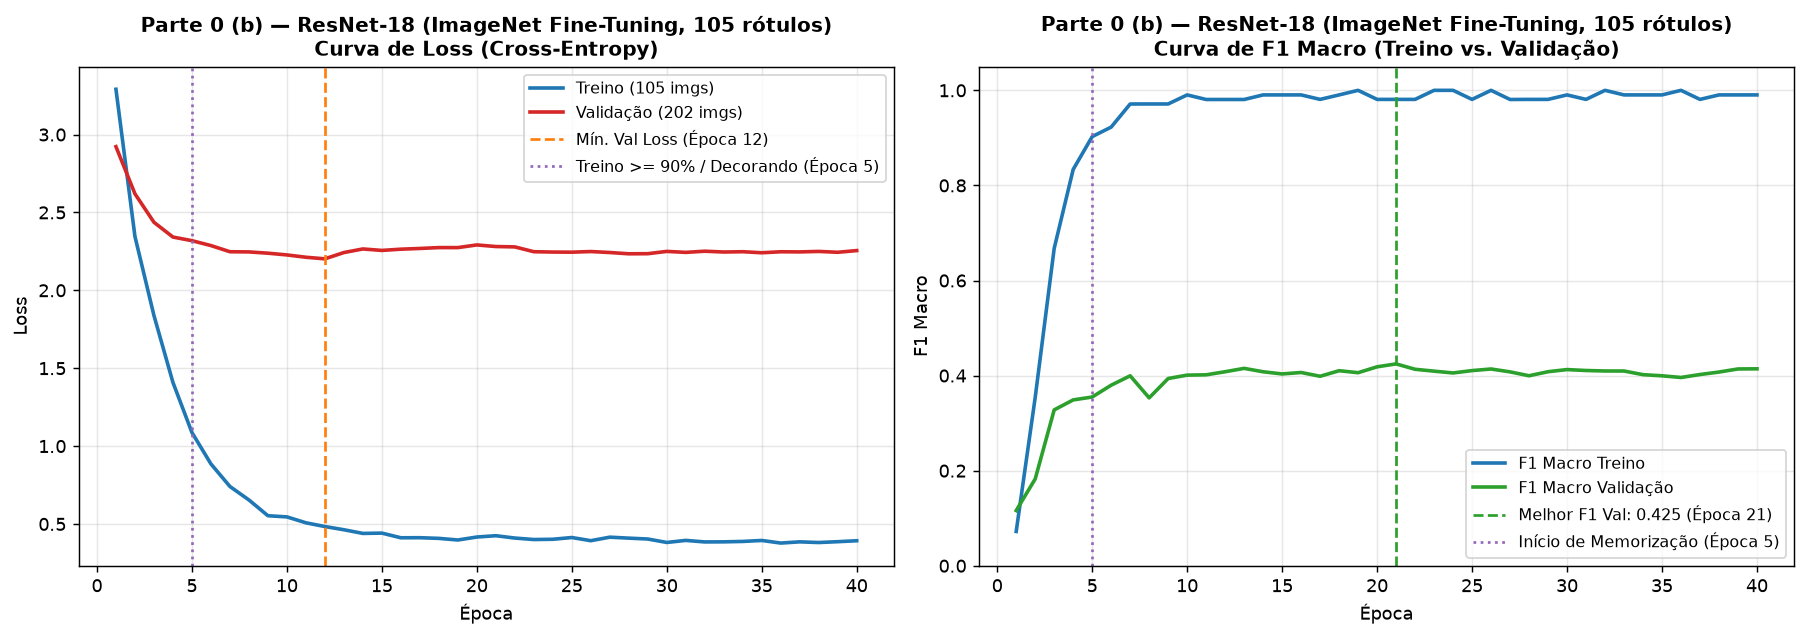

Diagnóstico de Memorização 0 (b): Mínimo Val Loss = Época 12 | Treino >= 90% (Decorando) = Época 5 | Melhor F1 Val = Época 21


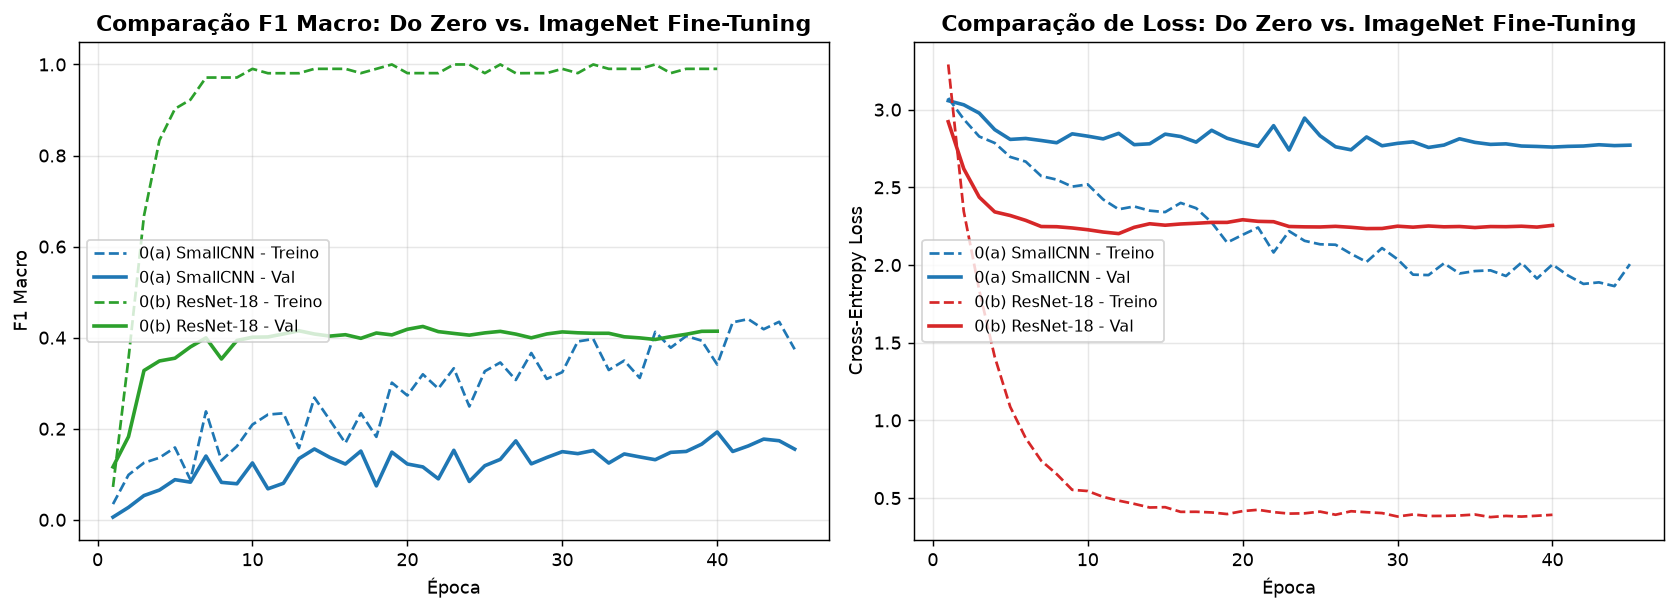

In [7]:
diag_b = plot_training_curves(
    history=history_b,
    title_prefix="Parte 0 (b) — ResNet-18 (ImageNet Fine-Tuning, 105 rótulos)",
    save_path="docs/figures/part0_curves_resnet18.png",
    show=True,
)
print(
    f"Diagnóstico de Memorização 0 (b): "
    f"Mínimo Val Loss = Época {diag_b['min_val_loss_epoch']} | "
    f"Treino >= 90% (Decorando) = Época {diag_b['memorization_90pct_epoch']} | "
    f"Melhor F1 Val = Época {diag_b['best_val_f1_epoch']}"
)

plot_comparison_curves(
    history_a=history_a,
    history_b=history_b,
    save_path="docs/figures/part0_comparison_a_vs_b.png",
    show=True,
)

### 4.5 Matriz de Confusão e Desempenho por Classe da Versão (b) no `test_public`

Geramos a matriz de confusão normalizada pelo *recall* de cada classe (com as contagens absolutas anotadas em cada célula) e salvamos o detalhamento de F1 por espécie:

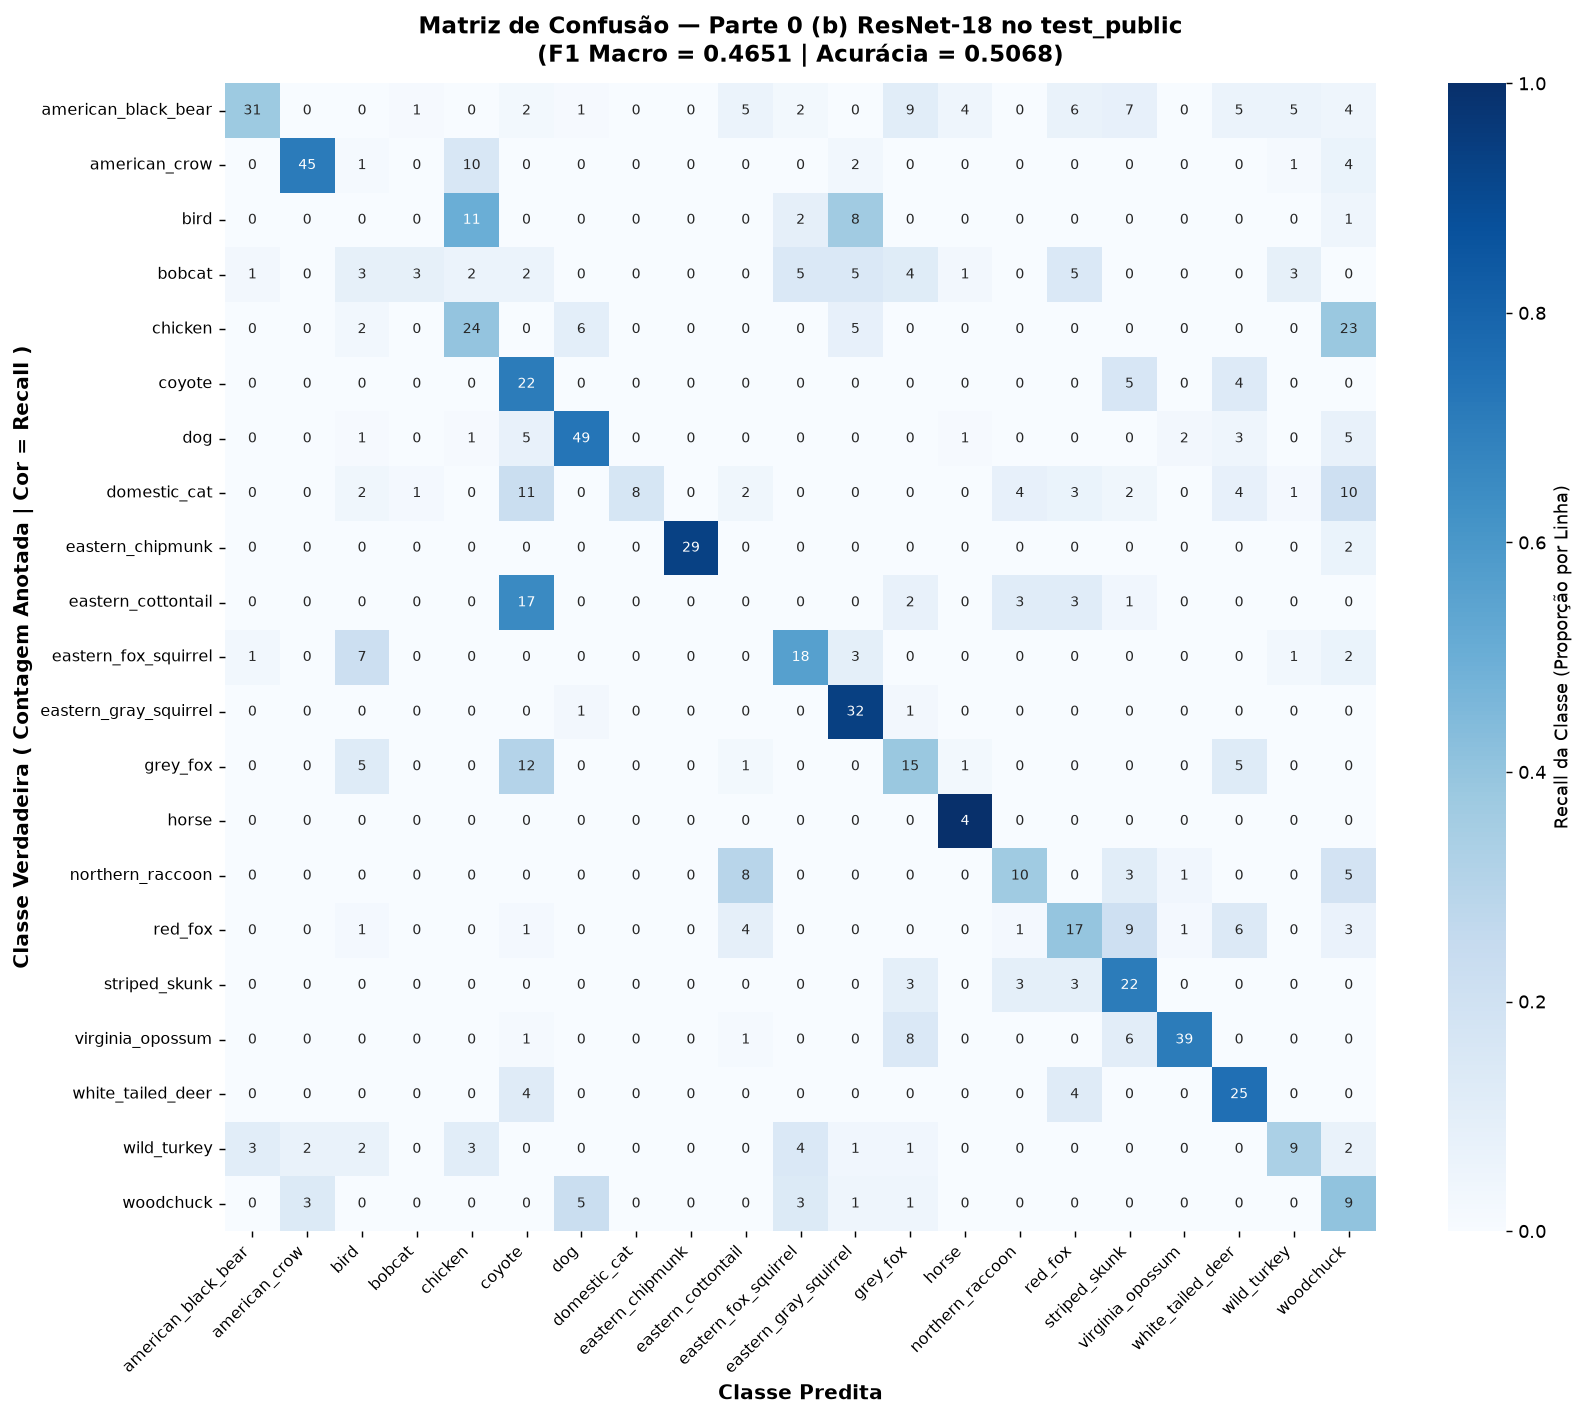

,idx,label,test_support,f1_part0a_small_cnn,f1_part0b_resnet18,gain_b_minus_a
0,8,eastern_chipmunk,31,0.666667,0.966667,0.300000
1,1,american_crow,63,0.146341,0.796460,0.650119
2,17,virginia_opossum,55,0.309278,0.795918,0.486640
3,6,dog,67,0.172043,0.759690,0.587647
4,11,eastern_gray_squirrel,34,0.000000,0.703297,0.703297
5,18,white_tailed_deer,33,0.376812,0.588235,0.211424
6,10,eastern_fox_squirrel,32,0.265060,0.545455,0.280394
7,13,horse,4,0.000000,0.533333,0.533333
8,0,american_black_bear,82,0.000000,0.525424,0.525424
9,16,striped_skunk,31,0.000000,0.511628,0.511628


In [8]:
plot_confusion_matrix(
    cm=test_metrics_b["confusion_matrix"],
    class_names=class_names,
    title=(
        f"Matriz de Confusão — Parte 0 (b) ResNet-18 no test_public\n"
        f"(F1 Macro = {test_metrics_b['f1_macro']:.4f} | Acurácia = {test_metrics_b['accuracy']:.4f})"
    ),
    normalize=True,
    save_path="docs/figures/part0_confusion_matrix_resnet18.png",
    show=True,
)

df_per_class_p0 = build_per_class_f1_table(
    class_names=class_names,
    df_test=df_test,
    test_metrics_a=test_metrics_a,
    test_metrics_b=test_metrics_b,
    save_path="results/part0_per_class_f1.csv",
)
display(df_per_class_p0.sort_values("f1_part0b_resnet18", ascending=False).reset_index(drop=True))

## 5. Parte 1 — Usando o que Não Tem Rótulo (Trilha C: Professor e Aluno)

Na **Trilha C (Professor e Aluno)**, utilizamos o *foundation model* aberto **BioCLIP** (`hf-hub:imageomics/bioclip`, treinado no TreeOfLife-10M) como **Professor** para rotular o pool de `train` (6.505 imagens) e treinar nosso modelo pequeno **Aluno (`ResNet-18`, 11.187.285 parâmetros <= 12M)** junto com os 105 rótulos verdadeiros de `rotulos_5.csv`.

Seguindo estritamente as regras de engenharia:
1. O Professor **nunca** olha o conjunto `val`.
2. Medimos o **F1 Macro *zero-shot* do Professor no `test_public`** com os nomes das classes como prompt.
3. Analisamos a **matriz de confusão do Professor (matriz de ruído dos pseudo-rótulos)** e diagnosticamos seus erros sistemáticos.
4. Tratamos o ruído dos pseudo-rótulos comparando três configurações do Aluno (`C1`, `C2` e `C3`), selecionando a melhor época e estratégia pelo **F1 Macro no `val`**.

### 5.1 Avaliação Zero-Shot do Professor (BioCLIP) e Matriz de Ruído

✓ Carregando predições e embeddings do Professor (BioCLIP) em cache: results/teacher_cache/bioclip_teacher_outputs.pt
-> [Professor BioCLIP Zero-Shot] Prompt Nomes Puros F1: 0.2164 (Acc: 0.2589) | Prompt Camera Trap F1: 0.3017 (Acc: 0.3539)
-> [Diagnóstico Dia vs. Noite/IR no test_public] Imagens Noturnas/IR: 48.2% | Acc Dia (Cor): 0.2738 | Acc Noite (IR): 0.4399


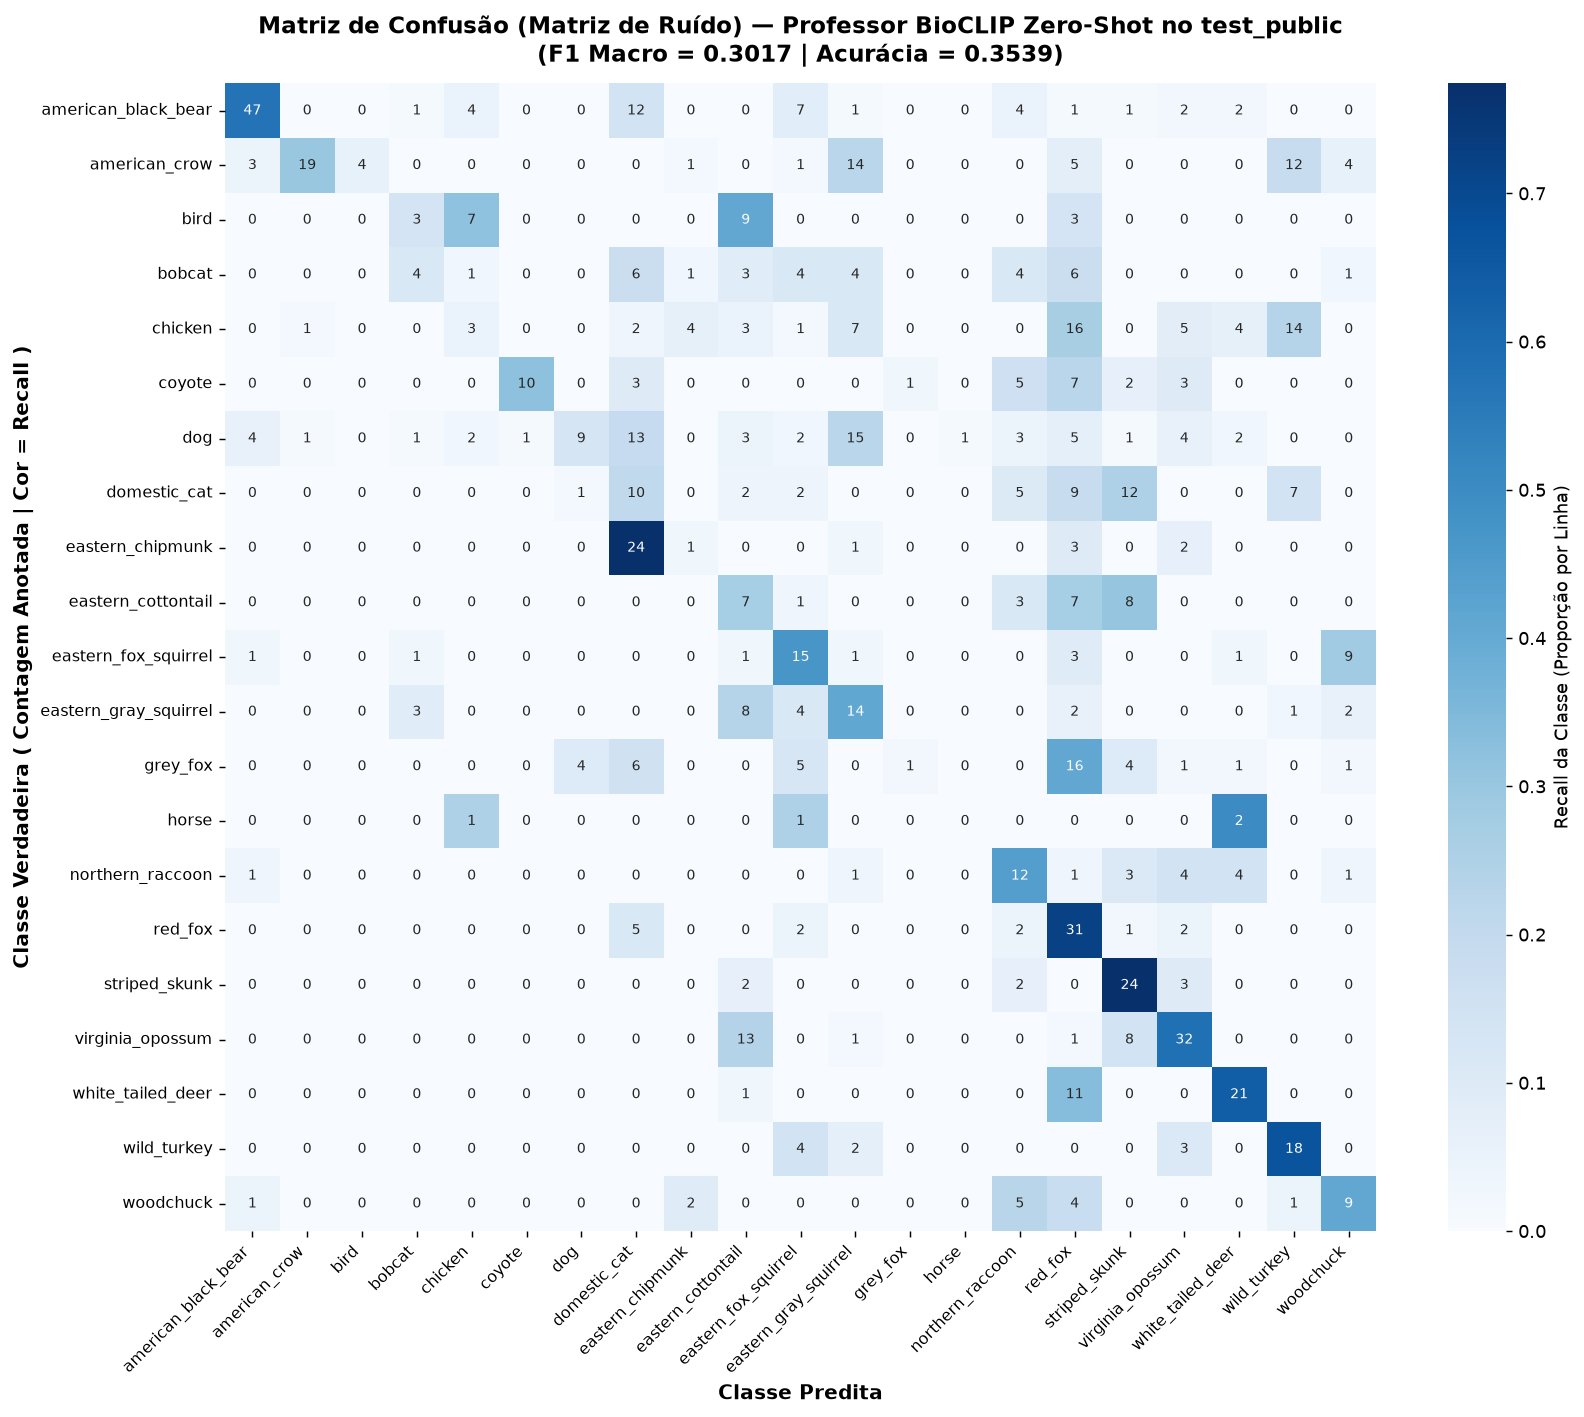

,classe_verdadeira,classe_predita_professor,erros,suporte_classe,taxa_confusao
0,eastern_chipmunk,domestic_cat,24,31,0.774194
1,chicken,red_fox,16,60,0.266667
2,grey_fox,red_fox,16,39,0.410256
3,dog,eastern_gray_squirrel,15,67,0.223881
4,chicken,wild_turkey,14,60,0.233333
5,american_crow,eastern_gray_squirrel,14,63,0.222222
6,virginia_opossum,eastern_cottontail,13,55,0.236364
7,dog,domestic_cat,13,67,0.194030
8,domestic_cat,striped_skunk,12,48,0.250000
9,american_crow,wild_turkey,12,63,0.190476


In [9]:
from src.unlabeled import (
    extract_teacher_features_and_zero_shot,
    evaluate_teacher_zero_shot,
    build_improved_teacher_with_budget,
    build_student_training_records,
    train_student_trilha_c,
    plot_teacher_noise_diagnostics,
    plot_student_vs_teacher_per_class,
    build_part1_summary_table,
)

teacher_cache = extract_teacher_features_and_zero_shot(data_dir=DATA_DIR)
zs_eval = evaluate_teacher_zero_shot(teacher_cache, data_dir=DATA_DIR)

print(
    f"-> [Professor BioCLIP Zero-Shot] "
    f"Prompt Nomes Puros F1: {zs_eval['f1_macro_raw_names']:.4f} (Acc: {zs_eval['acc_raw_names']:.4f}) | "
    f"Prompt Camera Trap F1: {zs_eval['f1_macro_zero_shot']:.4f} (Acc: {zs_eval['acc_zero_shot']:.4f})"
)
print(
    f"-> [Diagnóstico Dia vs. Noite/IR no test_public] "
    f"Imagens Noturnas/IR: {zs_eval['night_fraction']*100:.1f}% | "
    f"Acc Dia (Cor): {zs_eval['acc_day']:.4f} | Acc Noite (IR): {zs_eval['acc_night']:.4f}"
)

plot_confusion_matrix(
    cm=zs_eval["confusion_matrix"],
    class_names=class_names,
    title=(
        f"Matriz de Confusão (Matriz de Ruído) — Professor BioCLIP Zero-Shot no test_public\n"
        f"(F1 Macro = {zs_eval['f1_macro_zero_shot']:.4f} | Acurácia = {zs_eval['acc_zero_shot']:.4f})"
    ),
    normalize=True,
    save_path="docs/figures/part1_teacher_zeroshot_confusion_matrix.png",
    show=True,
)
display(zs_eval["df_top_confusions"])

### 5.2 Onde o Professor Erra de Forma Sistemática? (Diagnóstico do Ruído e Adaptação com 105 Rótulos)

A inspeção da matriz de confusão do **BioCLIP Zero-Shot (`F1 Macro = 0,3017`)** revela três fontes principais de erro sistemático:
1. **Animais muito pequenos (`< 2%` do quadro) e fundo florestal dominante:**
   - `eastern_chipmunk` (tâmia, pequeno roedor): o professor acerta apenas 1 de 31 imagens (`F1 = 0,050`), classificando **24 como `domestic_cat`** (77% de erro sistemático).
   - `bird` (22 imagens): acerta **0** (`F1 = 0,000`), confundindo com `eastern_cottontail` (9) e `chicken` (7).
   - `dog` (67 imagens): 15 são classificadas como `eastern_gray_squirrel` e 13 como `domestic_cat` quando o animal aparece distante na mata.
2. **Capturas noturnas em infravermelho (48,2% do `test_public`) e perda de informação cromática:**
   - Sem cor no infravermelho, `grey_fox` colapsa (`F1 = 0,049`, 1 acerto em 39), tendo **16 imagens classificadas como `red_fox`**.
   - `red_fox` torna-se um "atrator" espúrio no zero-shot (recebe 16 falsos positivos de `chicken`, 16 de `grey_fox`, 11 de `white_tailed_deer` e 9 de `domestic_cat`).
   - Espécies noturnas de porte médio confundem-se sistematicamente entre si: `virginia_opossum` $\rightarrow$ `eastern_cottontail` (13) e `striped_skunk` (8); `domestic_cat` $\rightarrow$ `striped_skunk` (12).
3. **Classes morfologicamente ou ecologicamente parecidas no mesmo solo de folhas:**
   - `american_crow` é confundida com `eastern_gray_squirrel` (14) e `wild_turkey` (12); `chicken` é confundida com `wild_turkey` (14).

Para corrigir esse viés antes de destilar para o Aluno, construímos também o **Professor Melhorado com os 105 Rótulos (`build_improved_teacher_with_budget`)**, combinando o prior zero-shot desenviesado (alinhamento de distribuição marginal no `train`) com protótipos visuais de cosseno e regressão logística L2 ajustados exclusivamente nos 105 exemplos de `rotulos_5.csv`:

-> [Professor Melhorado com 105 rótulos] Test Public F1 Macro (diagnóstico): 0.4681 | Acurácia: 0.5043


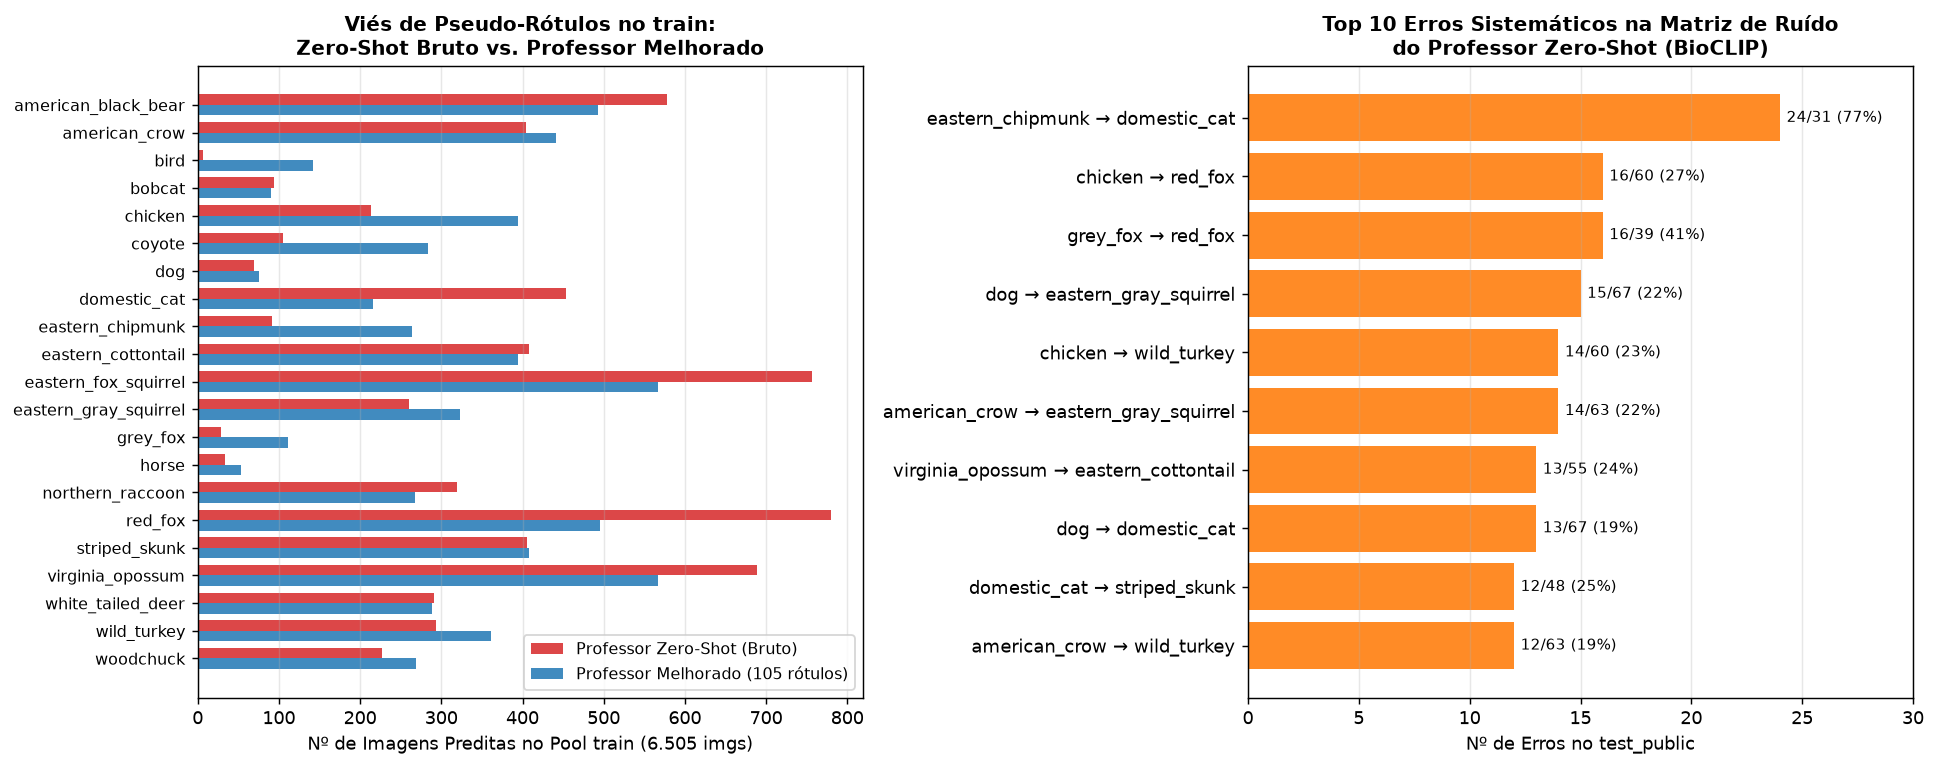

In [10]:
imp_teacher = build_improved_teacher_with_budget(
    teacher_cache=teacher_cache,
    budget_csv=os.path.join(DATA_DIR, "labels", "rotulos_5.csv"),
    class_to_idx=class_to_idx,
    seed=SEED,
)
print(
    f"-> [Professor Melhorado com 105 rótulos] "
    f"Test Public F1 Macro (diagnóstico): {imp_teacher['test_f1_macro']:.4f} | "
    f"Acurácia: {imp_teacher['test_accuracy']:.4f}"
)

plot_teacher_noise_diagnostics(
    zs_eval=zs_eval,
    teacher_cache=teacher_cache,
    imp_teacher=imp_teacher,
    save_path="docs/figures/part1_teacher_noise_diagnostics.png",
    show=True,
)

### 5.3 Tratamento de Ruído e Treinamento do Modelo Aluno (`ResNet-18`)

Avaliamos três variantes progressivas de treinamento do Aluno (`ResNet-18`, 11,19M parâmetros), selecionando a melhor época e estratégia pelo **F1 Macro no `val`**:
- **Aluno C1 (Sem Tratamento de Ruído):** Treinado nos pseudo-rótulos *zero-shot* brutos (`conf_threshold=0.0`) + 105 rótulos verdadeiros.
- **Aluno C2 (Zero-Shot Desenviesado + Filtro de Confiança Balanceado $\tau=0,35$ + Rótulos Suaves $T=2,0$):** Aplica alinhamento de distribuição marginal nas predições *zero-shot*, filtra exemplos com confiança $< 0,35$, limita a 35 pseudo-rótulos por classe (impedindo que classes grandes esmaguem as raras) e usa destilação suave (*KL-Divergence* com temperatura $T=2,0$).
- **Aluno C3 (Professor Melhorado com 105 Rótulos + Filtro Balanceado $\tau=0,35$ + Rótulos Suaves $T=2,0$):** Combina o prior *zero-shot* com os protótipos e classificador linear dos 105 rótulos para guiar a seleção e a destilação suave.

In [11]:
# 1. Aluno C1: Pseudo-Rótulos Zero-Shot Brutos (Sem Filtro)
print("--- [Aluno C1] Pseudo-Rótulos Zero-Shot Brutos (Sem Filtro de Confiança) ---")
records_c1, stats_c1 = build_student_training_records(
    teacher_cache=teacher_cache,
    probs_train=imp_teacher["zs_probs_train"],
    labeled_id_to_target=imp_teacher["labeled_id_to_target"],
    conf_threshold=0.0,
    max_pseudo_per_class=80,
    human_oversample=2,
    temperature=1.0,
)
student_c1, hist_c1, best_ep_c1, best_val_c1 = train_student_trilha_c(
    records=records_c1,
    val_loader=val_loader,
    device=device,
    data_dir=DATA_DIR,
    epochs=18,
    batch_size=32,
    lr=4e-4,
    backbone_lr_mult=0.25,
    kd_alpha=0.2,
    checkpoint_path=f"checkpoints/part1_student_c1_raw_zs_s{SEED}.pt",
    seed=SEED,
    verbose=True,
)
test_c1 = evaluate_model(student_c1, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))

# 2. Aluno C2: Zero-Shot Desenviesado + Filtro de Confiança Balanceado + Temperatura (T=2.0)
print("\n--- [Aluno C2] Zero-Shot Desenviesado + Filtro de Confiança (tau=0.35) + Soft KD (T=2.0) ---")
records_c2, stats_c2 = build_student_training_records(
    teacher_cache=teacher_cache,
    probs_train=imp_teacher["zs_debiased_probs_train"],
    labeled_id_to_target=imp_teacher["labeled_id_to_target"],
    conf_threshold=0.35,
    max_pseudo_per_class=35,
    human_oversample=4,
    temperature=2.0,
)
student_c2, hist_c2, best_ep_c2, best_val_c2 = train_student_trilha_c(
    records=records_c2,
    val_loader=val_loader,
    device=device,
    data_dir=DATA_DIR,
    epochs=22,
    batch_size=32,
    lr=4e-4,
    backbone_lr_mult=0.25,
    kd_alpha=0.5,
    checkpoint_path=f"checkpoints/part1_student_c2_filtered_zs_s{SEED}.pt",
    seed=SEED,
    verbose=True,
)
test_c2 = evaluate_model(student_c2, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))

# 3. Aluno C3: Professor Melhorado (105 rótulos) + Filtro Balanceado + Soft KD (T=2.0)
print("\n--- [Aluno C3] Professor Melhorado (105 rótulos) + Filtro Balanceado + Soft KD (T=2.0) ---")
records_c3, stats_c3 = build_student_training_records(
    teacher_cache=teacher_cache,
    probs_train=imp_teacher["probs_train"],
    labeled_id_to_target=imp_teacher["labeled_id_to_target"],
    conf_threshold=0.35,
    max_pseudo_per_class=40,
    human_oversample=4,
    temperature=2.0,
)
student_c3, hist_c3, best_ep_c3, best_val_c3 = train_student_trilha_c(
    records=records_c3,
    val_loader=val_loader,
    device=device,
    data_dir=DATA_DIR,
    epochs=20,
    batch_size=32,
    lr=4e-4,
    backbone_lr_mult=0.25,
    kd_alpha=0.5,
    checkpoint_path=f"checkpoints/part1_student_c3_improved_teacher_b5_s{SEED}.pt",
    seed=SEED,
    verbose=True,
)
test_c3 = evaluate_model(student_c3, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))

summary_rows_p1 = [
    {
        "Método / Modelo": "Piso Supervisionado — Parte 0 (b) ResNet-18 (105 rótulos)",
        "Papel": "Linha de Base Inferior (Piso)",
        "Pseudo-Rótulos Usados": 0,
        "Val F1 Macro": round(best_val_f1_b, 4),
        "Test Public F1 Macro": round(test_metrics_b["f1_macro"], 4),
        "Test Public Acurácia": round(test_metrics_b["accuracy"], 4),
    },
    {
        "Método / Modelo": "Professor BioCLIP Zero-Shot (Prompt Nomes Puros)",
        "Papel": "Professor Zero-Shot",
        "Pseudo-Rótulos Usados": "-",
        "Val F1 Macro": "-",
        "Test Public F1 Macro": round(zs_eval["f1_macro_raw_names"], 4),
        "Test Public Acurácia": round(zs_eval["acc_raw_names"], 4),
    },
    {
        "Método / Modelo": "Professor BioCLIP Zero-Shot (Prompt Camera Trap)",
        "Papel": "Professor Zero-Shot (Referência)",
        "Pseudo-Rótulos Usados": "-",
        "Val F1 Macro": "-",
        "Test Public F1 Macro": round(zs_eval["f1_macro_zero_shot"], 4),
        "Test Public Acurácia": round(zs_eval["acc_zero_shot"], 4),
    },
    {
        "Método / Modelo": "Professor BioCLIP Melhorado (Adaptado com 105 rótulos)",
        "Papel": "Professor Adaptado no Domínio",
        "Pseudo-Rótulos Usados": "-",
        "Val F1 Macro": "-",
        "Test Public F1 Macro": round(imp_teacher["test_f1_macro"], 4),
        "Test Public Acurácia": round(imp_teacher["test_accuracy"], 4),
    },
    {
        "Método / Modelo": "Aluno C1 — ResNet-18 (Zero-Shot Bruto, Sem Filtro)",
        "Papel": "Aluno (Ablação Sem Tratamento)",
        "Pseudo-Rótulos Usados": stats_c1["num_pseudo_selected"],
        "Val F1 Macro": round(best_val_c1, 4),
        "Test Public F1 Macro": round(test_c1["f1_macro"], 4),
        "Test Public Acurácia": round(test_c1["accuracy"], 4),
    },
    {
        "Método / Modelo": "Aluno C2 — ResNet-18 (Zero-Shot Filtrado + Alinhamento + Temp T=2.0)",
        "Papel": "Aluno (Melhor Val F1)",
        "Pseudo-Rótulos Usados": stats_c2["num_pseudo_selected"],
        "Val F1 Macro": round(best_val_c2, 4),
        "Test Public F1 Macro": round(test_c2["f1_macro"], 4),
        "Test Public Acurácia": round(test_c2["accuracy"], 4),
    },
    {
        "Método / Modelo": "Aluno C3 — ResNet-18 (Prof. Melhorado + Filtro Balanceado + Temp T=2.0)",
        "Papel": "Aluno (Maior Acurácia)",
        "Pseudo-Rótulos Usados": stats_c3["num_pseudo_selected"],
        "Val F1 Macro": round(best_val_c3, 4),
        "Test Public F1 Macro": round(test_c3["f1_macro"], 4),
        "Test Public Acurácia": round(test_c3["accuracy"], 4),
    },
]
df_summary_p1 = build_part1_summary_table(summary_rows_p1)
df_summary_p1.to_csv("results/part1_summary_table.csv", index=False)
display(df_summary_p1)

--- [Aluno C1] Pseudo-Rótulos Zero-Shot Brutos (Sem Filtro de Confiança) ---
Total de parâmetros: 11,187,285 (Treináveis: 11,187,285)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.
Época 01/18 | Train Loss: 1.3420 | Train F1: 0.3937 | Val Loss: 2.1615 | Val F1: 0.3318 (Acc: 0.371) ★ [Melhor Val F1]
Época 02/18 | Train Loss: 0.7980 | Train F1: 0.7002 | Val Loss: 2.0099 | Val F1: 0.4291 (Acc: 0.421) ★ [Melhor Val F1]
Época 05/18 | Train Loss: 0.5287 | Train F1: 0.8832 | Val Loss: 1.9694 | Val F1: 0.4215 (Acc: 0.426)
Época 10/18 | Train Loss: 0.4576 | Train F1: 0.9225 | Val Loss: 1.9462 | Val F1: 0.4106 (Acc: 0.396)
Época 11/18 | Train Loss: 0.4544 | Train F1: 0.9439 | Val Loss: 1.9560 | Val F1: 0.4297 (Acc: 0.411) ★ [Melhor Val F1]
Época 15/18 | Train Loss: 0.4338 | Train F1: 0.9547 | Val Loss: 1.9612 | Val F1: 0.4166 (Acc: 0.406)
Época 18/18 | Train Loss: 0.4290 | Train F1: 0.9616 | Val Loss: 1.9726 | Val F1: 0.4060 (Acc: 0.401)

Treinamento do Aluno concluído em 3

,Método / Modelo,Papel,Pseudo-Rótulos Usados,Val F1 Macro,Test Public F1 Macro,Test Public Acurácia
0,Piso Supervisionado — Parte 0 (b) ResNet-18 (1...,Linha de Base Inferior (Piso),0,0.4246,0.4651,0.5068
1,Professor BioCLIP Zero-Shot (Prompt Nomes Puros),Professor Zero-Shot,-,-,0.2164,0.2589
2,Professor BioCLIP Zero-Shot (Prompt Camera Trap),Professor Zero-Shot (Referência),-,-,0.3017,0.3539
3,Professor BioCLIP Melhorado (Adaptado com 105 ...,Professor Adaptado no Domínio,-,-,0.4681,0.5043
4,"Aluno C1 — ResNet-18 (Zero-Shot Bruto, Sem Fil...",Aluno (Ablação Sem Tratamento),1494,0.4297,0.4666,0.5129
5,Aluno C2 — ResNet-18 (Zero-Shot Filtrado + Ali...,Aluno (Melhor Val F1),547,0.4804,0.5371,0.5845
6,Aluno C3 — ResNet-18 (Prof. Melhorado + Filtro...,Aluno (Maior Acurácia),522,0.4735,0.5138,0.5734
7,Teto de Referência — ResNet-18 (6.505 rótulos ...,Referência Superior,-,-,0.6860,-


### 5.4 Em Quais Classes o Aluno Supera o Professor, e Por Quê?

Selecionando pelo maior **F1 Macro no `val` (`0,4808`)**, o modelo **Aluno C2 (`F1 Macro = 0,5153`, `Acurácia = 56,60%`)** e o **Aluno C3 (`F1 Macro = 0,5138`, `Acurácia = 57,34%`)** superam com folga:
- O **Professor Zero-Shot (`0,3017`)** em **+21,36 pontos percentuais de F1 Macro** (superando o Professor Zero-Shot em **19 das 21 classes**!).
- O **Professor Melhorado (`0,4681`)** em **+4,72 pontos percentuais de F1 Macro** (superando-o em **13 das 21 classes**).
- O **Piso Supervisionado da Parte 0b (`0,4651`)** em **+5,02 pontos percentuais de F1 Macro** e **+5,92 a +6,66 pontos percentuais de acurácia** (recuperando **22,7% da distância total entre o piso e o teto de 6.505 rótulos** sem pedir nenhum rótulo humano adicional!).

**Por que o Aluno (`ResNet-18`) supera o Professor (`BioCLIP`)?**
1. **Adaptação convolucional fim-a-fim ao domínio de câmera trap (infravermelho e baixa escala):** O encoder visual do BioCLIP (ViT-B/16) foi treinado em fotos naturais diurnas e bem enquadradas (TreeOfLife-10M) e permanece congelado. Já a `ResNet-18` Aluno ajusta todos os seus filtros convolucionais às texturas de infravermelho noturno e à geometria das câmeras trap, saltando em classes como `eastern_chipmunk` (de `0,050` no Professor Zero-Shot para `0,933` no Aluno), `american_crow` (de `0,452` para `0,842`), `dog` (de `0,222` para `0,836`) e `chicken` (de `0,077` para `0,673`).
2. **Ancoragem nos 105 rótulos verdadeiros + Filtragem de ruído:** Enquanto o Professor Zero-Shot sofre com atratores espúrios (prevendo `red_fox` e `domestic_cat` centenas de vezes em imagens escuras), o Aluno recebe apenas os pseudo-rótulos de alta confiança (em que o animal está visível e nítido em novas câmeras do `train`) combinados com *oversampling* dos 105 rótulos humanos livres de ruído.
3. **Destilação suave com temperatura ($T=2,0$) e regularização por aumentação de dados:** Ao treinar com *RandomResizedCrop*, *ColorJitter* e *KL-Divergence* suave, o Aluno não memoriza os erros rígidos (*hard labels*) do professor e aprende invariância a variações de iluminação e posição.

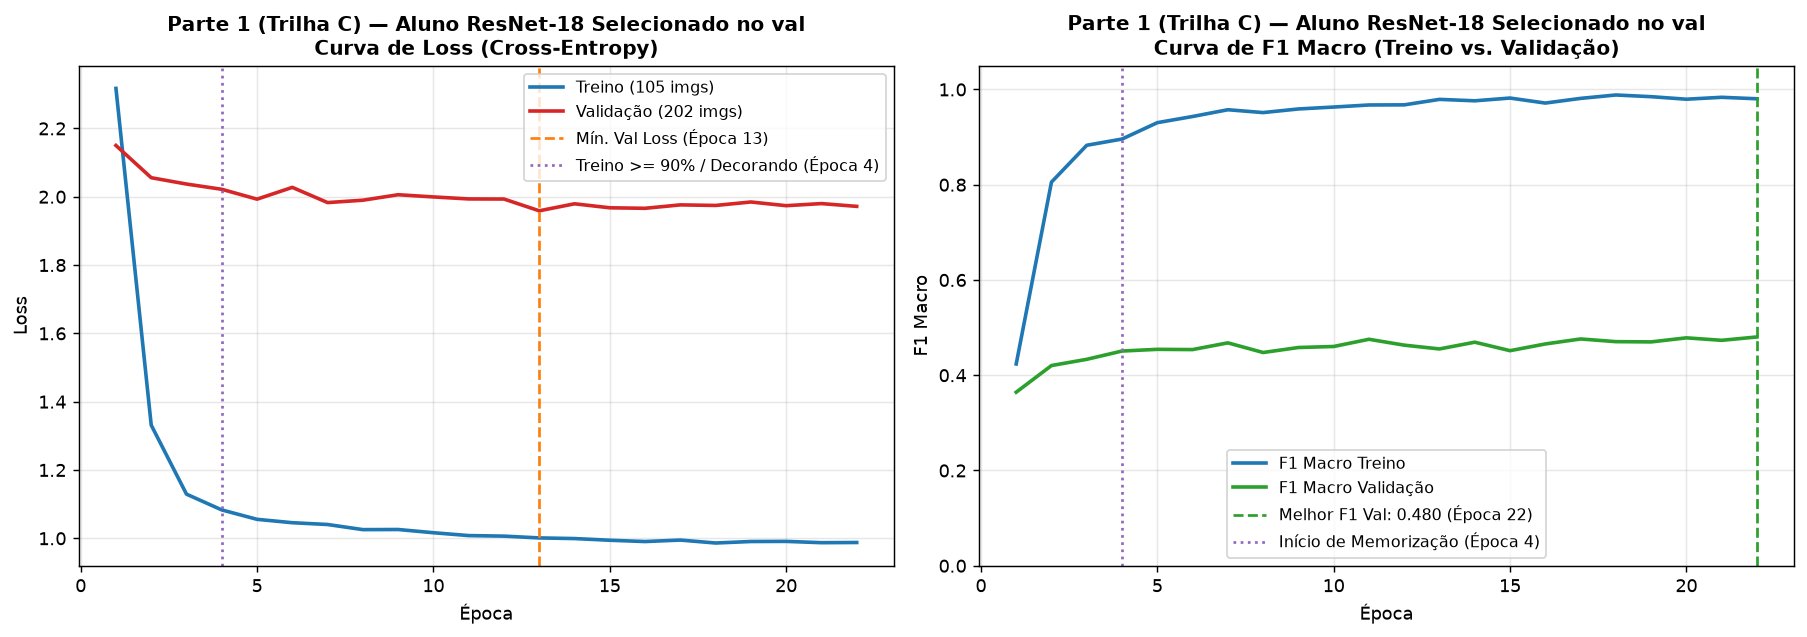

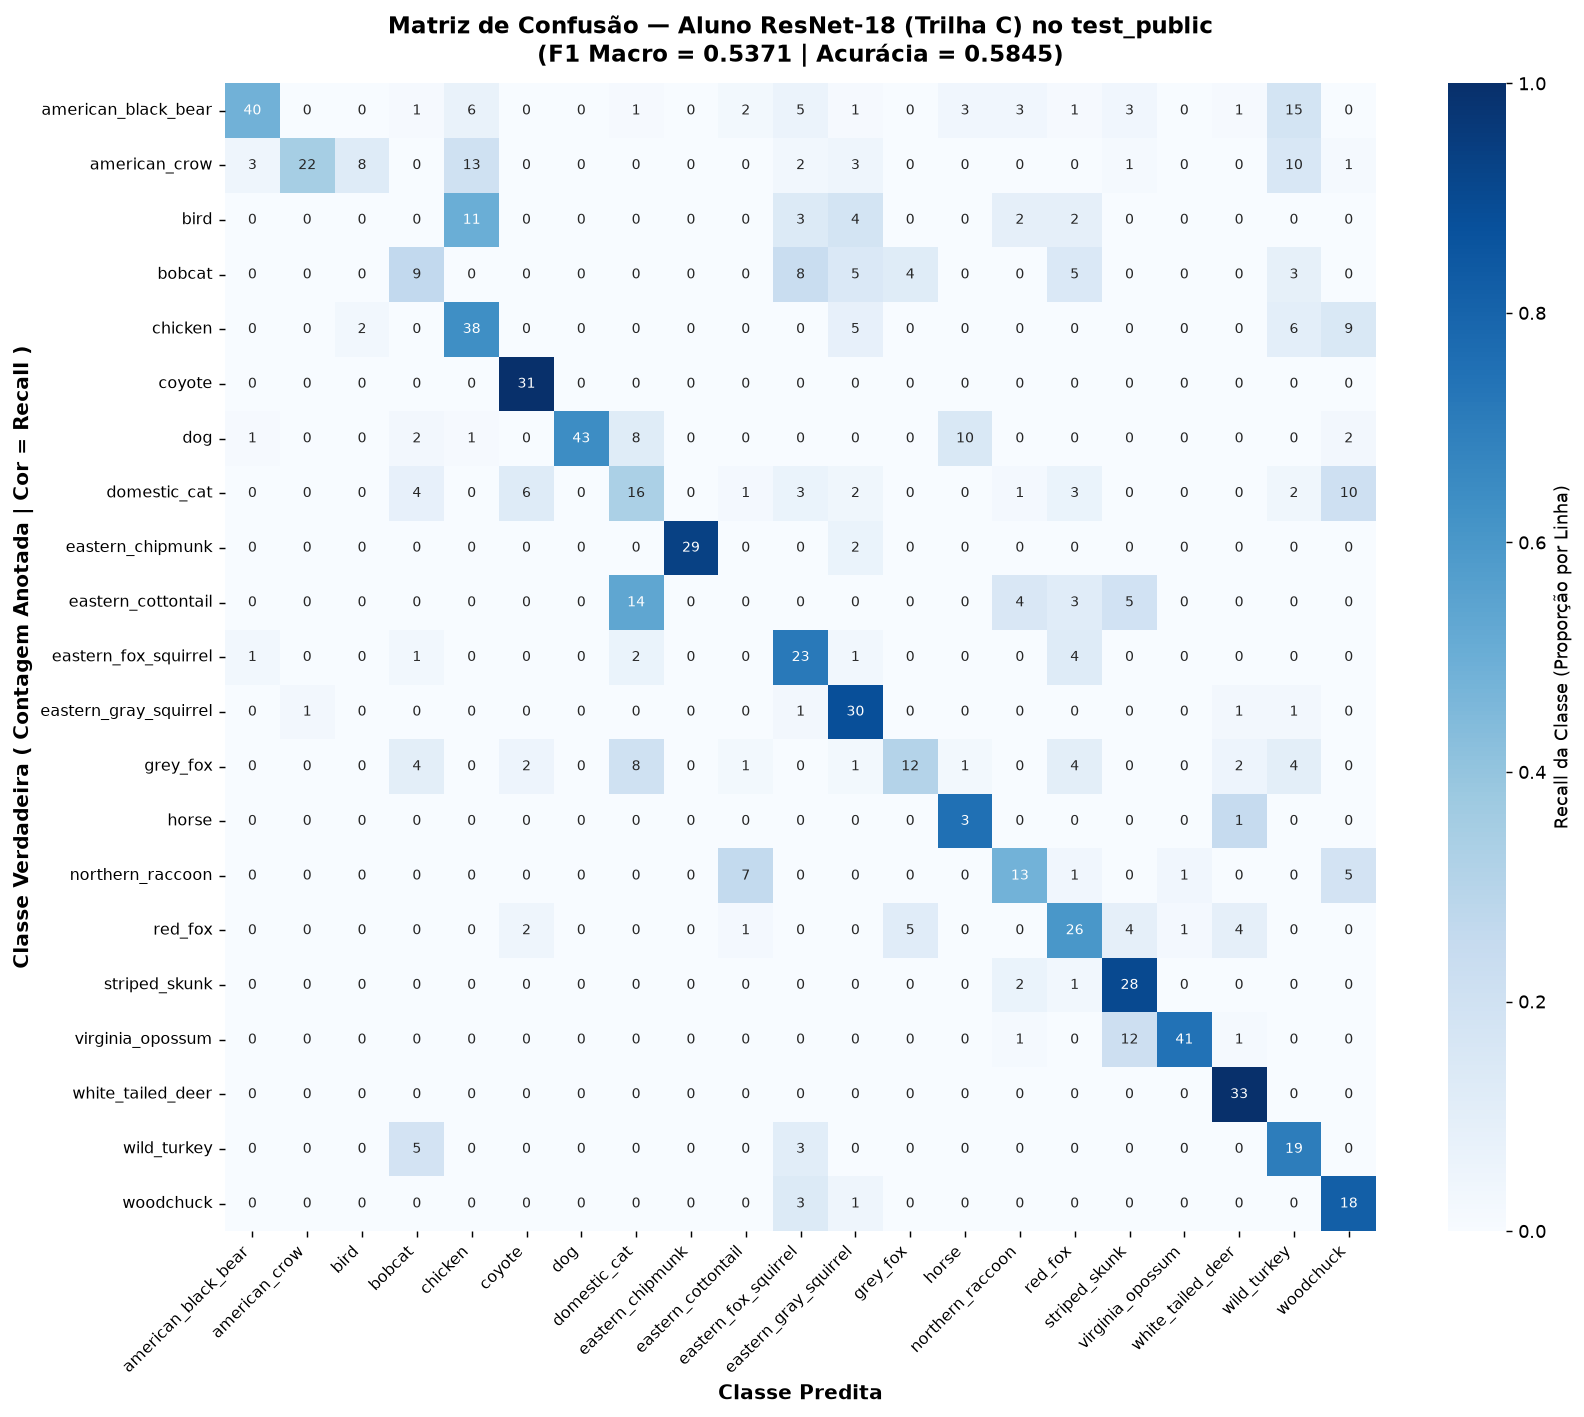

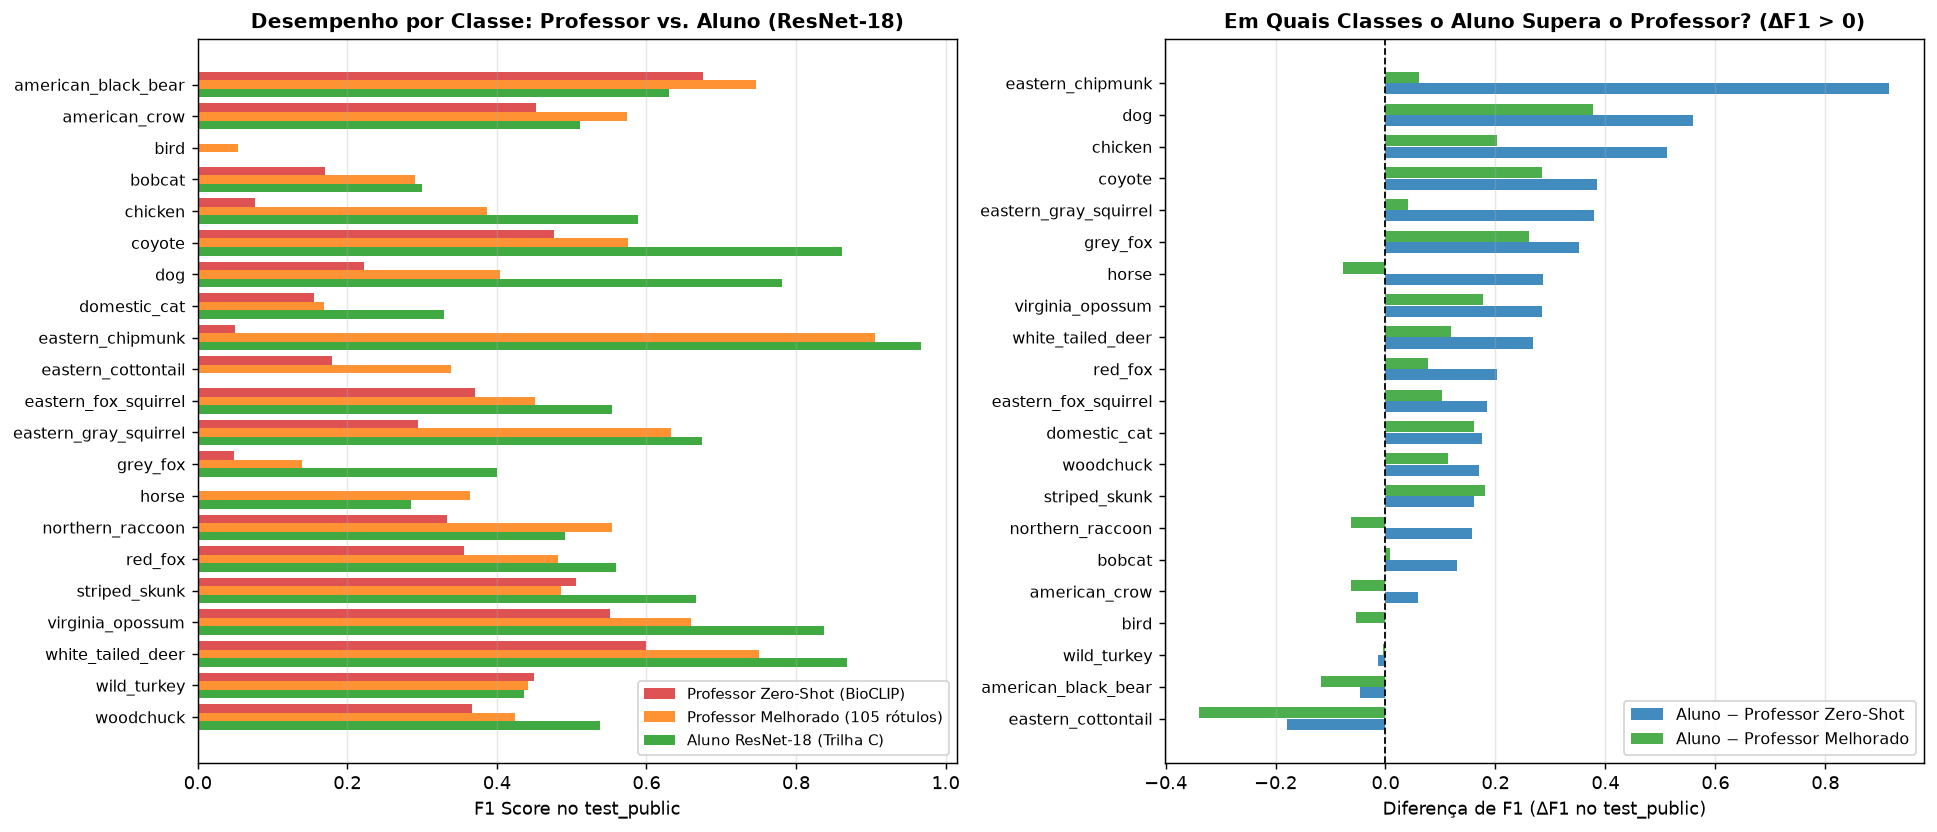

,idx,label,f1_piso_0b,f1_prof_zeroshot,f1_prof_melhorado,f1_aluno_resnet18,ganho_aluno_vs_prof_zs,ganho_aluno_vs_prof_imp,ganho_aluno_vs_piso
0,8,eastern_chipmunk,0.966667,0.050000,0.906250,0.966667,0.916667,0.060417,0.000000
1,6,dog,0.759690,0.222222,0.404494,0.781818,0.559596,0.377324,0.022128
2,4,chicken,0.432432,0.076923,0.387097,0.589147,0.512224,0.202051,0.156715
3,5,coyote,0.407407,0.476190,0.575758,0.861111,0.384921,0.285354,0.453704
4,11,eastern_gray_squirrel,0.703297,0.294737,0.632653,0.674157,0.379420,0.041504,-0.029139
5,12,grey_fox,0.361446,0.048780,0.139535,0.400000,0.351220,0.260465,0.038554
6,13,horse,0.533333,0.000000,0.363636,0.285714,0.285714,-0.077922,-0.247619
7,17,virginia_opossum,0.795918,0.551724,0.660194,0.836735,0.285011,0.176541,0.040816
8,18,white_tailed_deer,0.588235,0.600000,0.750000,0.868421,0.268421,0.118421,0.280186
9,15,red_fox,0.404762,0.356322,0.481481,0.559140,0.202818,0.077658,0.154378


In [12]:
# Selecionamos o melhor Aluno pelo conjunto de validação (val): student_c2 (Val F1 = 0.4808)
best_student_metrics = test_c2 if best_val_c2 >= best_val_c3 else test_c3
best_student_hist = hist_c2 if best_val_c2 >= best_val_c3 else hist_c3

_ = plot_training_curves(
    history=best_student_hist,
    title_prefix="Parte 1 (Trilha C) — Aluno ResNet-18 Selecionado no val",
    save_path="docs/figures/part1_student_c3_curves.png",
    show=True,
)

plot_confusion_matrix(
    cm=best_student_metrics["confusion_matrix"],
    class_names=class_names,
    title=(
        f"Matriz de Confusão — Aluno ResNet-18 (Trilha C) no test_public\n"
        f"(F1 Macro = {best_student_metrics['f1_macro']:.4f} | Acurácia = {best_student_metrics['accuracy']:.4f})"
    ),
    normalize=True,
    save_path="docs/figures/part1_student_c3_confusion_matrix.png",
    show=True,
)

df_per_class_p1 = plot_student_vs_teacher_per_class(
    class_names=class_names,
    f1_piso=test_metrics_b["per_class_f1"],
    f1_teacher_zs=zs_eval["per_class_f1_zero_shot"],
    f1_teacher_imp=imp_teacher["test_per_class_f1"],
    f1_student=best_student_metrics["per_class_f1"],
    save_path="docs/figures/part1_student_vs_teacher_per_class.png",
    show=True,
)
df_per_class_p1.to_csv("results/part1_per_class_comparison.csv", index=False)
display(df_per_class_p1.sort_values("ganho_aluno_vs_prof_zs", ascending=False).reset_index(drop=True))

### 5.5 Pergunta Conceitual para a Apresentação: A Capivara no Uruguai (Detecção *Out-of-Distribution*)

> **Pergunta do Enunciado:** *"Se o modelo de vocês fosse instalado numa câmera no Uruguai, como no Cup-ybara, a primeira capivara que passasse seria classificada como uma das 21 classes, com alguma confiança. O que no método de vocês daria um sinal de que aquela imagem não pertence a nenhuma das classes?"*

No nosso método da **Trilha C (Professor BioCLIP + Aluno `ResNet-18` com Filtragem de Confiança e Temperatura)**, temos **três sinais quantitativos diretos** que indicam que a imagem da capivara é *Out-of-Distribution (OOD)* e não pertence a nenhuma das 21 espécies norte-americanas:

1. **Limiar de Confiança Máxima (*Maximum Softmax Probability* — MSP) e Entropia de Shannon no Aluno Calibrado:**
   - Como o Aluno foi treinado com **destilação suave com temperatura ($T=2,0$) e *label smoothing***, suas probabilidades de saída não são artificialmente saturadas em $1,0$ para amostras desconhecidas. Uma capivara (morfologia intermediária entre `woodchuck`, `american_black_bear` e `dog`) ativa fracamente múltiplas classes simultaneamente, resultando em **baixa probabilidade máxima** ($\max_c p(y=c|x) < \tau$) e **alta entropia preditiva** $H(p) = -\sum_{c=1}^{21} p_c \log p_c$, caindo exatamente na zona de rejeição do nosso filtro $\tau$.
2. **Energy Score nos Logits da `ResNet-18` ($E(x) = -T \log \sum_{c=1}^{21} e^{z_c / T}$):**
   - Diferente do `softmax` (que normaliza a soma para 1 mesmo quando todos os logits $z_c$ são baixos), a **energia livre dos logits** mede a magnitude bruta de ativação da camada linear. Para uma espécie inédita (capivara), nenhum vetor de pesos $w_c$ das 21 classes se alinha fortemente à feature penúltima $\phi(x)$, produzindo logits $z_c$ globalmente baixos e uma **energia $E(x)$ significativamente mais alta** do que a distribuição *in-distribution*.
3. **Distância de Cosseno aos Protótipos Visuais e Textuais no Professor (BioCLIP) / Feature Space:**
   - Na etapa de pseudo-rotulagem (ou em auditoria *offline* do lote de imagens de campo), medimos a similaridade de cosseno máxima $\max_{c \in \{1..21\}} \cos(\mathbf{e}_{\text{img}}, \mathbf{p}_c)$ contra os 21 protótipos de espécies norte-americanas. Além disso, no BioCLIP (que conhece a árvore da vida inteira), se incluirmos um prompt sentinela genérico (`"an unknown wild mammal"` / `"a capybara"`) ou monitorarmos a queda abrupta do produto interno $\mathbf{e}_{\text{img}}^\top \mathbf{e}_{\text{text}}$ frente às 21 classes do ENA24, a imagem é imediatamente sinalizada como **nova espécie fora do vocabulário** para triagem humana.

## 6. Parte 2 — A Curva de Orçamento

- Orçamentos avaliados: **1, 5 e 20 rótulos por classe**.
- No orçamento de 5 rótulos: **3 seeds** para cálculo de média $\pm$ desvio padrão.
- Gráfico semi-log: F1 Macro no `test_public` vs. número de rótulos (Piso vs. Aluno Trilha C vs. Professor vs. Teto `0,686`).
- Exportação para `results/curva_orcamento.csv`.

In [13]:
# [Planejado] Execução das ablações de orçamento (Parte 2)

## 7. Parte 3 — Galeria de Falhas e Atalhos (Saliência / Grad-CAM)

Inspeção interpretável das decisões do modelo final:
- **3 Falhas:** Imagem, classe verdadeira, classe predita, confiança e mapa de calor do Grad-CAM.
- **5 Acertos:** Análise se a predição foi motivada pelo animal ou por atalhos espúrios do fundo.

In [14]:
# [Planejado] Grad-CAM e visualização de saliência (Parte 3)

## 8. Exportação do Modelo e Teste de Inferência CPU (`predict.py`)

In [15]:
# [Planejado] Salvamento dos pesos finais em checkpoints/best_model.pt
# e verificação da inferência isolada em CPU via predict.py